# Notebook 24 — Match the approved ESCM with additive synapses; then replace sensory support with STD

## Question and experimental contract

Can conventional **additive autaptic transmission with a 1 ms absolute refractory period** recover the approved model's persistence and competition? The original **approved benchmark** is kept intact: refreshed autapse ($I_{\rm exc}\leftarrow8s$), sensory support ($\tau_s=120$ ms), **no refractory period**, and surround inhibition gain $0.1$.

We proceed in two stages:

1. **Calibrate the additive + support candidate.** Keep membrane and camera parameters fixed, use $t_{\rm ref}=1$ ms, and vary only additive autapse strength $W$ and a common scale on the *existing* inhibitory kernel. Compare with the approved benchmark and the refreshed model with 1 ms refractory. Both baselines use their original inhibitory gain.
2. **Replace support with conventional short-term depression (STD)** in the most promising additive configuration. Remove the support state entirely. Keep the camera pathway additive and compare a small set of resource-depletion parameters, without retuning the network again.

The goal is not to force a successful outcome: the five geometry tests, isolated-controls criterion, and success definition are fixed *before* examining the candidates. We report failures and trade-offs. This is a **synthetic mechanistic test**, not yet full-camera validation. Brian2 must be installed in the notebook kernel.

## 1. Shared model and stimuli

Each pixel is one LIF neuron:

$$\tau_m\dot v_i=-v_i+I_{\mathrm{ext},i}+I_{\mathrm{exc},i}-I_{\mathrm{inh},i},\qquad v_i>1\Rightarrow v_i\leftarrow0.$$

Currents decay with time constants $3$, $5$, and $12$ ms for external, excitatory, and inhibitory currents respectively, while $\tau_m=10$ ms. Camera events add 22 to $I_{\rm ext}$, and surround inhibition uses the established weights $0.1\exp[-d^2/(2\cdot2.5^2)]$ for $1.5<d\le5.5$ pixels. The simulation step is $0.05$ ms.

Neuron differential equations and current decay continue to evolve during the absolute refractory interval. Synaptic transmission is event-driven. The initial network state is quiescent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"  # Many small simulations; avoid repeated C++ compilation.

width = height = 9
n = width * height
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))
dt_ms = 0.05

params = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms, tau_exc=5*b2.ms,
              tau_inh=12*b2.ms, tau_support=120*b2.ms,
              v_threshold=1.0, camera_gain=22.0)

# Geometry and stimulus conventions match the earlier spatial-generalization notebooks.
def pixels(coords):
    return np.array([y*width + x for x, y in coords], dtype=int)

shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]),
                 pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]),
                   pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]),
                 pixels([(x+3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}

# Directed connections: from every 'pre' pixel to each 'post' pixel in its surround.
dist = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((dist > 1.5) & (dist <= 5.5))
inhibition_weights = 0.1 * np.exp(-dist[post, pre]**2 / (2*2.5**2))
assert all(len(a) == len(b) == 5 and len(set(a) | set(b)) == 10
           for a, b in shapes.values())
print(f"{n} neurons; {len(pre)} directed surround-inhibitory synapses")

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


81 neurons; 3620 directed surround-inhibitory synapses


## 2. Implement the three synaptic mechanisms

The **approved reference** and the **additive + support candidate** use the same sensory state: $\dot s=-s/\tau_s$, with $s\leftarrow1$ after each camera event. At self-spikes, the reference overwrites $I_{\rm exc}\leftarrow 8s$; the additive candidate instead transmits $I_{\rm exc}\leftarrow I_{\rm exc}+Ws$.

In the **STD candidate**, there is **no support variable**. The recurrent synapse instead tracks available resources $x$:

$$\dot x=(1-x)/\tau_{\rm rec},\quad
I_{\rm exc}\leftarrow I_{\rm exc}+Wx,\quad
x\leftarrow x(1-U)\qquad\text{at each presynaptic spike}.$$

Here $W$ is the initial synaptic-current increment ($x=1$). In a conventional Tsodyks–Markram parameterization, the increment is $W_{\rm max}Ux$; equivalently our $W=W_{\rm max}U$. The camera drive is unchanged, but **STD is depleted by self-spikes and recovers during silence**, whereas sensory support is refreshed by camera events and decays during silence. They are not mathematically interchangeable, which is precisely what we test.

In [2]:
def simulate(schedule, mode="refresh", weight=8., refractory_ms=0.,
             inhibition_scale=1., duration_ms=120., tau_rec_ms=120., use=0.3,
             trace_pixel=None):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms*b2.ms

    event_ids, event_times = [], []
    for ids, pulses in schedule:
        for t in pulses:
            event_ids.extend(np.asarray(ids, dtype=int))
            event_times.extend([t]*len(ids))
    order = np.argsort(event_times, kind="stable")
    camera = b2.SpikeGeneratorGroup(n, np.asarray(event_ids, dtype=int)[order],
                                    np.asarray(event_times, dtype=float)[order]*b2.ms)

    equations = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode != "std":
        equations += "dsupport/dt = -support/tau_support : 1\n"
    neurons = b2.NeuronGroup(n, equations, threshold="v > v_threshold", reset="v = 0",
                             refractory=refractory_ms*b2.ms if refractory_ms else False,
                             method="exact", namespace=params)

    camera_update = "Iext_post += camera_gain"
    if mode != "std":
        camera_update += "; support_post = 1"
    camera_syn = b2.Synapses(camera, neurons, on_pre=camera_update, namespace=params)
    camera_syn.connect(j="i")

    if mode == "refresh":
        autapse = b2.Synapses(neurons, neurons,
                             on_pre="Iexc_post = autapse_gain*support_post",
                             namespace={"autapse_gain": float(weight)})
    elif mode == "additive":
        autapse = b2.Synapses(neurons, neurons,
                             on_pre="Iexc_post += autapse_gain*support_post",
                             namespace={"autapse_gain": float(weight)})
    elif mode == "std":
        autapse = b2.Synapses(neurons, neurons,
                             "dx/dt = (1-x)/tau_rec : 1 (event-driven)",
                             on_pre="Iexc_post += autapse_gain*x; x *= (1-use)",
                             namespace={"autapse_gain": float(weight),
                                        "tau_rec": tau_rec_ms*b2.ms, "use": float(use)})
    else:
        raise ValueError(mode)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    if mode == "std":
        autapse.x = 1

    inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
    inhibition.connect(i=pre, j=post)
    inhibition.w = inhibition_weights*inhibition_scale

    spikes = b2.SpikeMonitor(neurons)
    objects = [camera, neurons, camera_syn, autapse, inhibition, spikes]
    if trace_pixel is not None:
        variables = ["Iext", "Iexc", "Iinh", "v"]
        if mode != "std":
            variables.append("support")
        state = b2.StateMonitor(neurons, variables, record=[int(trace_pixel)])
        objects.append(state)
    b2.Network(*objects).run(duration_ms*b2.ms)
    out = {"t": np.asarray(spikes.t/b2.ms), "i": np.asarray(spikes.i, dtype=int)}
    if trace_pixel is not None:
        out["trace_t"] = np.asarray(state.t/b2.ms)
        for var in variables:
            out[var] = np.asarray(getattr(state, var)[0])
    return out

## 3. Verify the benchmark and define the outcome measure

Old shape pixels receive camera events at $2,4,6$ ms; new shape pixels at $20,22,24$ ms. We measure neuronal spikes in **two disjoint windows**, $[32,42)$ and $[42,52)$ ms. Each geometry is simulated with **old-only**, **new-only**, and **both** stimuli.

A geometry is **eligible** if every pixel in each isolated shape produces at least 2 spikes in *each* window. Conditional on eligibility, replacement succeeds if **all five old pixels are silent**, **all five new pixels remain active**, and no unrelated pixels spike during either window. Counting only spikes in the stated windows prevents display artifacts from influencing the metric.

This criterion is strict: a configuration that fades before the test is *not* rewarded for suppressing the old shape.

In [3]:
def pixel_counts(run, ids, a, b):
    mask = (run["t"] >= a) & (run["t"] < b)
    return np.bincount(run["i"][mask], minlength=n)[ids]

old_pulses = (2., 4., 6.)
new_pulses = (20., 22., 24.)
windows = ((32., 42.), (42., 52.))

def evaluate(mode, weight, refractory_ms, inhibition_scale=1., tau_rec_ms=120., use=0.3):
    rows = []
    for shape, (old, new) in shapes.items():
        kwargs = dict(mode=mode, weight=weight, refractory_ms=refractory_ms,
                      inhibition_scale=inhibition_scale, tau_rec_ms=tau_rec_ms, use=use)
        old_run = simulate([(old, old_pulses)], **kwargs)
        new_run = simulate([(new, new_pulses)], **kwargs)
        both_run = simulate([(old, old_pulses), (new, new_pulses)], **kwargs)
        background = np.setdiff1d(np.arange(n), np.r_[old, new])
        oc = np.array([pixel_counts(old_run, old, a, b) for a, b in windows])
        nc = np.array([pixel_counts(new_run, new, a, b) for a, b in windows])
        ob = np.array([pixel_counts(both_run, old, a, b) for a, b in windows])
        nb = np.array([pixel_counts(both_run, new, a, b) for a, b in windows])
        bg = np.array([pixel_counts(both_run, background, a, b) for a, b in windows])
        eligible = bool(np.all(oc >= 2) and np.all(nc >= 2))
        old_silent = int(np.count_nonzero(np.all(ob == 0, axis=0)))
        new_active = int(np.count_nonzero(np.all(nb >= 2, axis=0)))
        off_target = int(np.count_nonzero(np.any(bg > 0, axis=0)))
        rows.append(dict(geometry=shape, eligible=eligible, old_silent=old_silent,
                         new_active=new_active, off_target=off_target,
                         success=bool(eligible and old_silent == 5 and
                                      new_active == 5 and off_target == 0)))
    return pd.DataFrame(rows)

def score(rows):
    return dict(eligible=int(rows.eligible.sum()), successes=int(rows.success.sum()),
                old_silent=round(float(rows.old_silent.mean()), 2),
                new_active=round(float(rows.new_active.mean()), 2),
                off_target=int(rows.off_target.sum()))

baselines = {}
for title, ref_ms in tqdm((("Approved: refresh, 0 ms", 0.),
                           ("Refresh + 1 ms", 1.)), desc="Reference networks"):
    baselines[title] = evaluate("refresh", 8., ref_ms)
    print(title, score(baselines[title]))

reference_table = pd.DataFrame([dict(model=name, **score(rows)) for name, rows in baselines.items()])
display(reference_table)

Reference networks:  50%|█████     | 1/2 [00:04<00:04,  4.36s/it]

Approved: refresh, 0 ms {'eligible': 5, 'successes': 3, 'old_silent': 4.8, 'new_active': 4.8, 'off_target': 0}


Reference networks: 100%|██████████| 2/2 [00:08<00:00,  4.40s/it]

Refresh + 1 ms {'eligible': 5, 'successes': 3, 'old_silent': 4.4, 'new_active': 5.0, 'off_target': 0}


,model,eligible,successes,old_silent,new_active,off_target
0,"Approved: refresh, 0 ms",5,3,4.8,4.8,0
1,Refresh + 1 ms,5,3,4.4,5.0,0


## 4. Search for a calibrated additive + support network

Fix $t_{\rm ref}=1$ ms. Vary additive gain $W\in\{2.25,2.5,2.75,3.0,3.25\}$ and inhibitory-kernel multiplier $g_I\in\{1,1.5,2,3\}$. The inhibition profile and neuronal equations are unchanged. This is a bounded grid of **20 settings**, not a global optimum search.

We rank results first by the number of strict replacement successes and number of eligible geometry controls, then by preservation of new activity and suppression of old activity. Eligibility is displayed separately so an apparent improvement cannot come from spontaneous fading. If no configuration matches the benchmark, we report that directly instead of silently broadening the search.

In [4]:
weights = (2.25, 2.5, 2.75, 3., 3.25)
inhibition_scales = (1., 1.5, 2., 3.)
search_rows = []
for w in tqdm(weights, desc="Additive weights"):
    for g in inhibition_scales:
        result = evaluate("additive", w, 1., inhibition_scale=g)
        search_rows.append(dict(weight=w, inhibition_scale=g, **score(result)))
search = pd.DataFrame(search_rows).sort_values(
    ["successes", "eligible", "new_active", "old_silent", "off_target"],
    ascending=[False, False, False, False, True]).reset_index(drop=True)
display(search)

best = search.iloc[0]
best_weight = float(best.weight)
best_inhibition = float(best.inhibition_scale)
print(f"Highest-ranked additive candidate: W={best_weight:g}, inhibitory scale={best_inhibition:g}")
print("Approved baseline:", score(baselines["Approved: refresh, 0 ms"]))
print("Matched strict replacements:",
      int(best.successes) >= int(reference_table.loc[0, "successes"]))

Additive weights: 100%|██████████| 5/5 [01:10<00:00, 14.13s/it]


,weight,inhibition_scale,eligible,successes,old_silent,new_active,off_target
0,3.00,1.0,5,0,0.0,5.0,0
1,3.25,1.0,5,0,0.0,5.0,0
2,3.25,1.5,5,0,0.0,4.6,0
3,2.75,1.0,4,0,0.0,4.8,0
4,3.00,1.5,4,0,1.0,4.6,0
5,3.25,2.0,4,0,1.0,3.6,0
6,2.75,1.5,2,0,3.2,4.2,0
7,3.00,2.0,2,0,3.0,3.2,0
8,2.50,1.0,0,0,1.2,4.8,0
9,2.25,1.0,0,0,4.6,4.6,0


Highest-ranked additive candidate: W=3, inhibitory scale=1
Approved baseline: {'eligible': 5, 'successes': 3, 'old_silent': 4.8, 'new_active': 4.8, 'off_target': 0}
Matched strict replacements: False


## 5. Test persistence, firing rate, and fading on the selected configuration

The geometry test alone does not establish a useful dynamics. We now stimulate one isolated pixel at $2,4,6$ ms and continue the simulation to 300 ms with **no further camera input**. We compare the approved benchmark, refreshed + 1 ms, and the selected additive candidate. The minimum interspike interval must respect refractoriness, firing rates should remain interpretable, and activity should eventually stop after the input ceases.

These tests are **post-selection diagnostics**; the choice of best candidate is based only on the fixed geometry score above.

,model,spikes,last_spike_ms,min_isi_ms,spikes_after_100ms
0,Approved refresh,54,89.20,0.25,0
1,Refresh + 1 ms,42,93.55,1.00,0
2,Additive calibrated,72,85.70,1.00,0


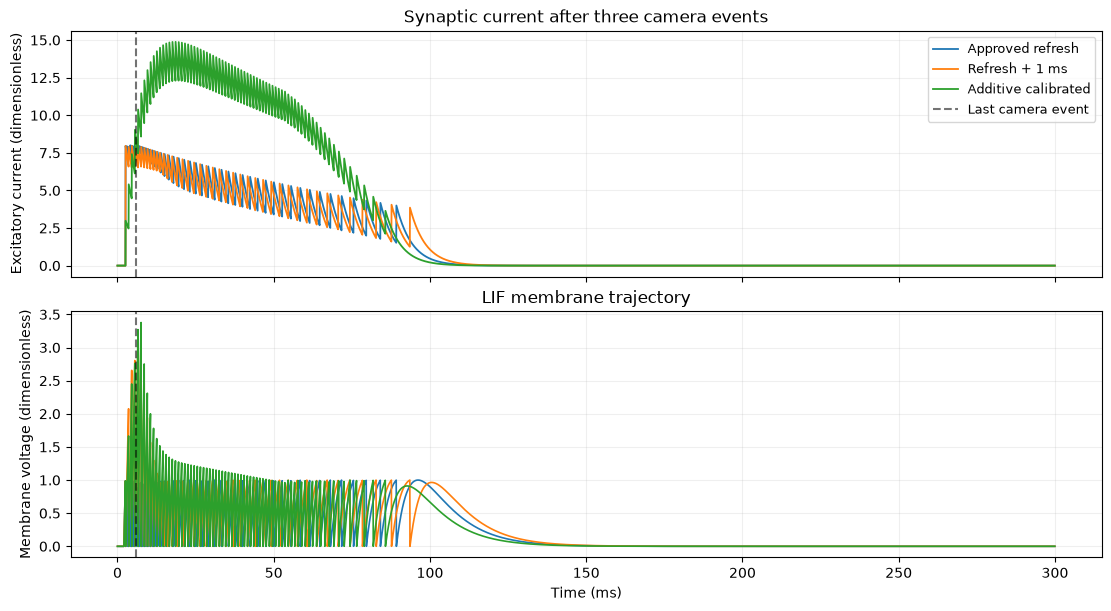

In [5]:
center = int(pixels([(4,4)])[0])
individual = [(np.array([center]), (2., 4., 6.))]
traces = {}
models = [("Approved refresh", dict(mode="refresh", weight=8., refractory_ms=0.)),
          ("Refresh + 1 ms", dict(mode="refresh", weight=8., refractory_ms=1.)),
          ("Additive calibrated", dict(mode="additive", weight=best_weight,
                                        refractory_ms=1., inhibition_scale=best_inhibition))]
measurements = []
for label, settings in models:
    r = simulate(individual, duration_ms=300., trace_pixel=center, **settings)
    traces[label] = r
    t = r["t"][r["i"] == center]
    isi = np.diff(t)
    measurements.append(dict(model=label, spikes=len(t),
                             last_spike_ms=round(float(t[-1]),2) if len(t) else np.nan,
                             min_isi_ms=round(float(isi.min()),3) if len(isi) else np.nan,
                             spikes_after_100ms=int(np.count_nonzero(t>=100))))
display(pd.DataFrame(measurements))

fig, axes = plt.subplots(2,1,figsize=(11,6),sharex=True,constrained_layout=True)
for label,r in traces.items():
    axes[0].plot(r["trace_t"], r["Iexc"], label=label, lw=1.3)
    axes[1].plot(r["trace_t"], r["v"], label=label, lw=1.2)
for ax in axes:
    ax.axvline(6.,color="black",linestyle="--",alpha=.55,label="Last camera event")
    ax.grid(alpha=.2)
axes[0].set(ylabel="Excitatory current (dimensionless)",title="Synaptic current after three camera events")
axes[1].set(xlabel="Time (ms)",ylabel="Membrane voltage (dimensionless)",title="LIF membrane trajectory")
axes[0].legend(loc="upper right",fontsize=9)
plt.show()

## 6. Direct comparison: replace support by STD

Now remove sensory support entirely and use a depressing recurrent synapse. The camera still provides **only additive external current**. We retain $t_{\rm ref}=1$ ms, the selected inhibitory scale, and the selected initial recurrent increment $W$ to isolate what happens when the memory mechanism is replaced.

Test depletion fractions $U\in\{0.2,0.5\}$ and recovery constants $\tau_{\rm rec}\in\{60,120,240\}$ ms. An STD resource trace **recovers toward 1 when unused**, rather than decaying toward 0. Thus STD is not guaranteed to cause fading or to distinguish recently stimulated pixels. The experiment explicitly checks for these failures.

In [6]:
std_rows=[]
for use in tqdm((0.2, 0.5),desc="STD depletion fraction"):
    for tau_rec in (60.,120.,240.):
        result = evaluate("std", best_weight, 1., inhibition_scale=best_inhibition,
                          tau_rec_ms=tau_rec, use=use)
        r = simulate(individual, mode="std", weight=best_weight, refractory_ms=1.,
                     inhibition_scale=best_inhibition, tau_rec_ms=tau_rec, use=use,
                     duration_ms=300.)
        times = r["t"][r["i"]==center]
        std_rows.append(dict(use=use, tau_rec_ms=tau_rec, **score(result),
                             last_spike_ms=round(float(times[-1]),2) if len(times) else np.nan,
                             spikes_after_100ms=int(np.count_nonzero(times>=100))))
std_table = pd.DataFrame(std_rows).sort_values(
    ["successes", "eligible", "new_active", "old_silent"],
    ascending=False).reset_index(drop=True)
display(std_table)

comparison = pd.concat([
    reference_table,
    pd.DataFrame([dict(model=f"Additive + support (W={best_weight:g}, g={best_inhibition:g})",
                       **{key:best[key] for key in ("eligible","successes","old_silent","new_active","off_target")})]),
    pd.DataFrame([dict(model=f"STD (U={row.use:g}, tau={row.tau_rec_ms:g}ms)",
                       **{key:row[key] for key in ("eligible","successes","old_silent","new_active","off_target")})
                  for _,row in std_table.iterrows()]),
],ignore_index=True)
for col in ("eligible","successes","off_target"):
    comparison[col] = comparison[col].astype(int)
display(comparison)

STD depletion fraction:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    't' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 6.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_rec" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will use the object from the group-specific namespace with the value 60. * msecond, but the name also refers to a variable in the run namespace with value '60.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    't' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 24.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_rec" refers to different objects in different namespaces used for resolving names in the context of group "synapses_1". Will us

,use,tau_rec_ms,eligible,successes,old_silent,new_active,off_target,last_spike_ms,spikes_after_100ms
0,0.2,60.0,0,0,5.0,0.0,0,16.75,0
1,0.2,120.0,0,0,5.0,0.0,0,17.10,0
2,0.2,240.0,0,0,5.0,0.0,0,17.60,0
3,0.5,60.0,0,0,5.0,0.0,0,13.90,0
4,0.5,120.0,0,0,5.0,0.0,0,14.10,0
5,0.5,240.0,0,0,5.0,0.0,0,14.20,0


,model,eligible,successes,old_silent,new_active,off_target
0,"Approved: refresh, 0 ms",5,3,4.8,4.8,0
1,Refresh + 1 ms,5,3,4.4,5.0,0
2,"Additive + support (W=3, g=1)",5,0,0.0,5.0,0
3,"STD (U=0.2, tau=60ms)",0,0,5.0,0.0,0
4,"STD (U=0.2, tau=120ms)",0,0,5.0,0.0,0
5,"STD (U=0.2, tau=240ms)",0,0,5.0,0.0,0
6,"STD (U=0.5, tau=60ms)",0,0,5.0,0.0,0
7,"STD (U=0.5, tau=120ms)",0,0,5.0,0.0,0
8,"STD (U=0.5, tau=240ms)",0,0,5.0,0.0,0


## 7. Interpretation and next decision

The **approved benchmark** is the unchanged refreshed model at 0 ms refractory. A promising additive candidate should approximately match its **eligible isolated controls, strict replacement count, current/firing dynamics, and fading**, not just one metric. The 1 ms refreshed condition measures how much refractoriness alone changes the benchmark.

The STD stage tests a separate mechanistic claim: whether depletion/recovery **without an explicit sensory-support trace** reproduces both activity persistence and replacement. Because the resource variable recovers toward availability during inactivity, STD may weaken recurrent excitation during active firing but cannot by itself encode *time since last camera event*. Treat similar geometry scores as insufficient unless the isolated-neuron fading and firing-rate diagnostics also agree.

**Non-claims:** This small parameter grid is not proof of global optimality, and the five synthetic shapes are not a substitute for validation on the full event-camera recording. Do not change the approved model based on this notebook alone. If no additive configuration reaches the benchmark, record the negative finding rather than quietly changing the evaluation windows or criteria.